# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Укажите устройство, выбранную ветку, использованные внешние источники и нерешённые задачи (если есть).

Устройство: Google Colab (GPU T4)

Выбранная ветка атак: 5.2

Бонусные задания: 7.1 - 7.5

Нерешённые задачи: 5.3

Внешние источники: ноутбуки и записи с семинаров, документация PyTorch


In [135]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
MPS available:   False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [4]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.3', '7.4', '7.5'}        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [5]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [6]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [ ]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape

    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride=stride, padding=padding, dilation=dilation)
    cols = F.unfold(x, kernel_size=(kh, kw), dilation=dilation, padding=padding, stride=stride)

    weight_g = weight.view(groups, C_out // groups, -1)
    cols_g = cols.view(B, groups, -1, H_out * W_out)

    out = torch.einsum('gok, bgkl -> bgol', weight_g, cols_g)
    out = out.reshape(B, C_out, H_out, W_out)

    if bias is not None:
        out = out + bias.view(1, -1, 1, 1)

    return out

In [8]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [9]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ.** При padding = k // 2 размер выхода равен входу, поэтому cols больше x ровно в k^2 раз: при k=3 в 9 раз, при k=5 в 25, при k=7 в 49. Из-за этого память и вычисления im2col растут квадратично O(k^2), тогда как сложность FFT-свёртки O(HW log(HW)) не зависит от размера ядра. Поэтому im2col хорош на малых ядрах (3x3), а на больших (от 7x7) FFT-свёртка выигрывает за счёт отсутствия огромного оверхеда по памяти. Ограничение: выигрыш FFT работает при stride=1; при stride > 1 или малых ядрах накладные расходы БПФ делают его невыгодным

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [10]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        sh, sw = pair(s)
        ph, pw = pair(p)
        kh, kw = weight.shape[2], weight.shape[3]
        H, W = x.shape[2], x.shape[3]
        H_out, W_out = grad_out.shape[2], grad_out.shape[3]

        grad_x = None
        if ctx.needs_input_grad[0]:
            op_h = H - ((H_out - 1) * sh - 2 * ph + kh)
            op_w = W - ((W_out - 1) * sw - 2 * pw + kw)
            grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w))

        grad_w = None
        if ctx.needs_input_grad[1]:
            cols = F.unfold(x, kernel_size=(kh, kw), dilation=1, padding=p, stride=s)
            g_flat = grad_out.reshape(grad_out.shape[0], grad_out.shape[1], -1)
            grad_w = torch.einsum('bol, bkl -> ok', g_flat, cols).reshape_as(weight)

        grad_b = None
        if ctx.needs_input_grad[2]:
            grad_b = grad_out.sum(dim=(0, 2, 3))

        return grad_x, grad_w, grad_b, None, None

In [11]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ.** Для размеров H = 7 и H = 8 свёртка со stride 2 и padding 1 даёт одинаковый H_out = 4, так как ((H - 1) // 2) + 1 в обоих случаях равно 4. По формуле op_H = H - (2 * H_out - 1) получаем output_padding = 0 для H = 7 и output_padding = 1 для H = 8. Смысл output_padding в backward - вернуть отброшенный при целочисленном делении остаток и однозначно восстановить исходный размер входа

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def receptive_field(layers):
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [ ]:
def empirical_rf(model, in_channels=1, size=96):
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    y = model(x)

    H_out, W_out = y.shape[2], y.shape[3]
    ch, cw = H_out // 2, W_out // 2

    target = y[0, :, ch, cw].sum()
    grad_x, = torch.autograd.grad(target, x)

    active = (grad_x[0] != 0).any(dim=0)
    coords = torch.nonzero(active)
    if len(coords) == 0:
        return (0, 0)

    h_span = coords[:, 0].max().item() - coords[:, 0].min().item() + 1
    w_span = coords[:, 1].max().item() - coords[:, 1].min().item() + 1

    return (h_span, w_span)

In [14]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ.** Усредняющие ядра с положительными весами 1/k^2 без активаций гарантируют, что градиент нигде не занулится, поэтому носитель градиента в точности равен теоретическому RF (conv3x3 x4 дал 9, conv-pool - 18, strided - 17, dilated - 15). При MaxPool градиент идёт только через точку максимума (argmax), делая внутренность области разреженной, однако крайние пути всё равно достигают границ окна, поэтому общий размер bounding box остаётся прежним (9, 18, 17, 15). Ограничение: совпадают только внешние границы рамки, но плотность связей внутри при MaxPool значительно ниже

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [ ]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    x = torch.randn(n_inputs, in_channels, size, size, requires_grad=True)
    y = model(x)

    ch, cw = y.shape[2] // 2, y.shape[3] // 2
    target = y[:, :, ch, cw].sum()
    grad_x, = torch.autograd.grad(target, x)

    grad_map = grad_x.abs().mean(dim=0).sum(dim=0)

    p = grad_map.sum(dim=1)
    p = p / p.sum()

    coords = torch.arange(size, dtype=torch.float64, device=p.device)
    mean = (coords * p).sum()
    var = ((coords - mean) ** 2 * p).sum()

    return math.sqrt(max(var.item(), 0.0))

In [16]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [17]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


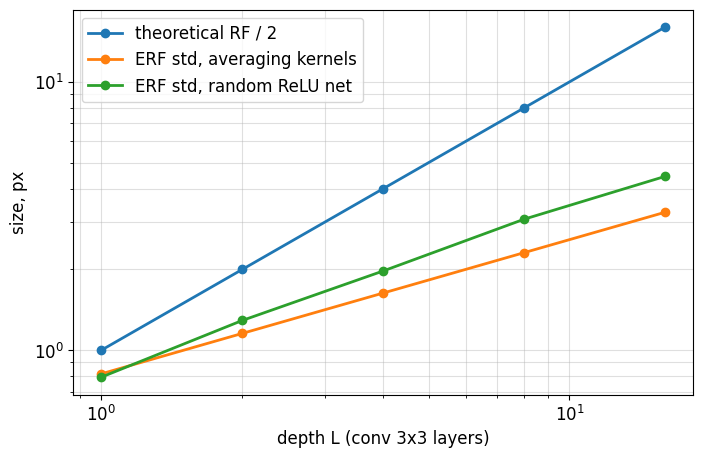

In [18]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ.** Теоретический RF растёт линейно с глубиной L (от 1 до 16, наклон 1 на log-log), а эффективный радиус усредняющей сети растёт как sqrt(L) (от 0.82 до 3.27, наклон 0.5). Поэтому отношение ERF к теоретическому RF падает как 1/sqrt(L), и влияние всё сильнее стягивается к центру. В сети с ReLU эффективный радиус растёт с тем же сублинейным темпом (наклон ~0.5), но шире усредняющей на всех глубинах (4.44 против 3.27 при L=16) из-за удвоенной дисперсии весов Kaiming и случайного разброса путей. Ограничение: замер сделан на случайной необученной сети; в процессе обучения форма поля может деформироваться под задачу

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [19]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps = eps
        self.momentum = momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            if self.num_batches_tracked is not None:
                self.num_batches_tracked.add_(1)

            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), unbiased=False)

            n = x.shape[0] * x.shape[2] * x.shape[3]
            unbiased_var = var * (n / (n - 1)) if n > 1 else var

            m = self.momentum if self.momentum is not None else (1.0 / float(self.num_batches_tracked))
            with torch.no_grad():
                self.running_mean.copy_((1 - m) * self.running_mean + m * mean)
                self.running_var.copy_((1 - m) * self.running_var + m * unbiased_var)

            x_norm = (x - mean.view(1, -1, 1, 1)) / torch.sqrt(var.view(1, -1, 1, 1) + self.eps)
        else:
            x_norm = (x - self.running_mean.view(1, -1, 1, 1)) / torch.sqrt(self.running_var.view(1, -1, 1, 1) + self.eps)

        return self.weight.view(1, -1, 1, 1) * x_norm + self.bias.view(1, -1, 1, 1)

In [20]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ.** Running-статистика оценивает генеральную дисперсию признаков по всему датасету для последующего инференса, поэтому требует несмещённой оценки (поправка Бесселя n / (n - 1)). Для нормировки текущего батча берётся смещённая дисперсия, чтобы выборочная дисперсия нормализованных значений строго равнялась единице. При B = 4 и карте 5x5 размер выборки n = 4 * 5 * 5 = 100, а поправка n / (n - 1) = 100 / 99 дает различие всего ~1.01%. При B = 2 и карте 1x1 выборка n = 2, поправка 2 / 1 даёт различие в 2 раза (100%). Ограничение: при сверхмалых размерах батча смещённая дисперсия сильно занижает реальный разброс, что приводит к рассинхрону статистик между train и eval

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ.**

In [21]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    fused = nn.Conv2d(
        conv.in_channels,
        conv.out_channels,
        conv.kernel_size,
        stride=conv.stride,
        padding=conv.padding,
        dilation=conv.dilation,
        groups=conv.groups,
        bias=True,
        padding_mode=conv.padding_mode,
        device=conv.weight.device,
        dtype=conv.weight.dtype,
    )
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    fused.weight.copy_(conv.weight * scale.view(-1, 1, 1, 1))

    b_conv = conv.bias if conv.bias is not None else torch.zeros(
        conv.out_channels, device=conv.weight.device, dtype=conv.weight.dtype
    )
    fused.bias.copy_(scale * (b_conv - bn.running_mean) + bn.bias)
    return fused


def fuse_sequential(seq):
    layers = list(seq)
    fused_layers = []
    i = 0
    while i < len(layers):
        if i + 1 < len(layers) and isinstance(layers[i], nn.Conv2d) and isinstance(layers[i + 1], nn.BatchNorm2d):
            fused_layers.append(fuse_conv_bn(layers[i], layers[i + 1]))
            i += 2
        else:
            fused_layers.append(copy.deepcopy(layers[i]))
            i += 1
    return nn.Sequential(*fused_layers)

In [ ]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [23]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [24]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 130.1 ms   fused: 125.6 ms   speedup 1.04x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ.** В режиме eval статистики BatchNorm зафиксированы, превращая его в поканальное аффинное преобразование, которое линейно объединяется с весами свёртки. В режиме train среднее и дисперсия зависят от текущего входного батча, делая операцию нелинейной, поэтому слить веса до подачи данных невозможно. Слияние устраняет промежуточное чтение/запись в память и оверхед вызова ядра; в эксперименте время прогона модели снизилось со 130.1 мс до 125.6 мс (ускорение 1.04x). Выигрыш зависит от того, ограничено ли выполнение памятью или вычислениями (memory-bound vs compute-bound): на CPU свёртка доминирует по вычислениям, давая скромный прирост (1.04x), тогда как на GPU при достаточной пропускной способности объединение даёт заметно больший процент ускорения

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ.**
Для $z = \mathrm{ReLU}(h)$ при симметричном распределении $\mathbb{E}[z^2] = 0.5 \cdot \mathrm{Var}(h)$, откуда условие сохранения дисперсии $n \cdot v \cdot 0.5 = 1$ даёт $v = 2 / n$ (инициализация Kaiming). Для $\tanh$ около нуля $z \approx h$, поэтому $\mathbb{E}[z^2] \approx \mathrm{Var}(h)$, что даёт условие $n \cdot v = 1$ и $v = 1 / n$ (инициализация Xavier).
Для дефолтной инициализации $\mathcal{U}(-1/\sqrt{n}, 1/\sqrt{n})$ дисперсия весов равна $v = 1 / (3n)$. Подставляя её в формулу для $\mathrm{ReLU}$, получаем $\mathrm{Var}(h) = \mathrm{Var}(h_{prev}) / 6$, то есть стандартное отклонение уменьшается в $\sqrt{6} \approx 2.45$ раза за слой (множитель $1 / \sqrt{6} \approx 0.408$, что совпало с замером в коде: $0.409$)

In [25]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width)
    stds = []
    for _ in range(depth):
        w = torch.empty(width, width)
        init(w)
        h = act(h @ w.T)
        stds.append(h.std().item())
    return stds

In [26]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.758


np.float64(0.40910241812972786)

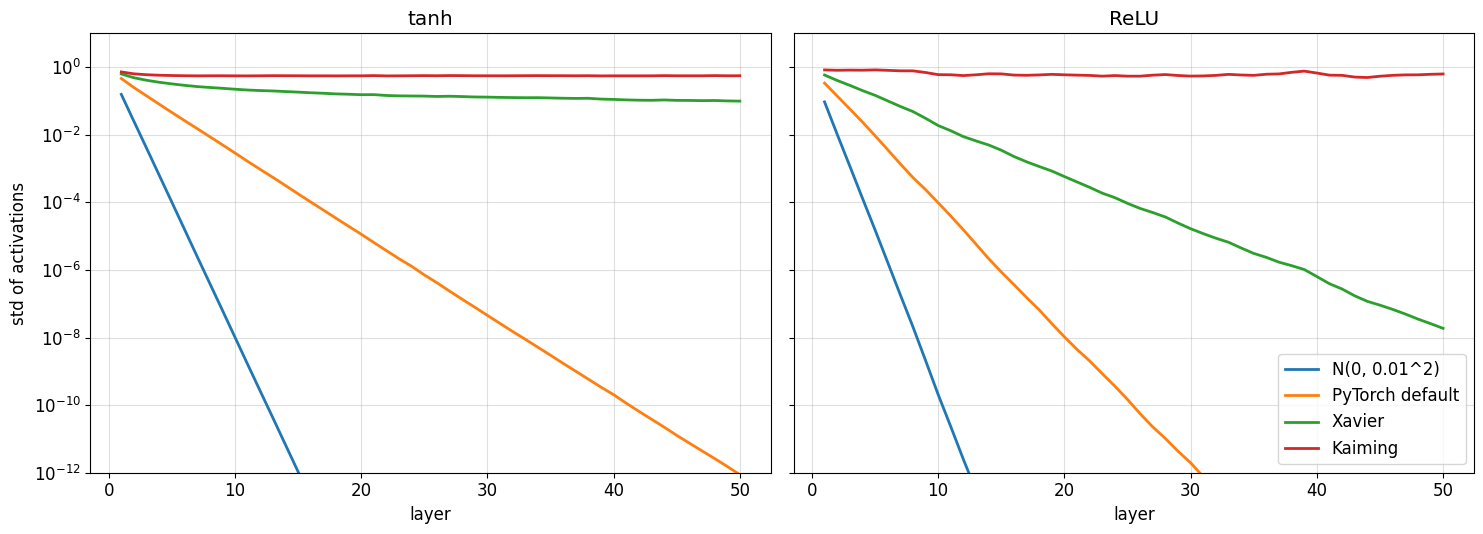

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ.** Масштаб на 50 слоях сохраняют пары (Kaiming, ReLU), где отношение std последнего слоя к первому составило 0.758, и (Xavier, tanh). При PyTorch default std экспоненциально затухает с множителем 0.41 за слой, падая на 50 слоях практически до нуля. Сети вроде ResNet с дефолтной инициализацией успешно обучаются благодаря skip-connections, которые передают градиенты и масштаб сигнала в обход слоёв, а также слоям BatchNorm, принудительно восстанавливающим единичную дисперсию активаций после каждого блока. Ограничение: без нормализации и остаточных связей глубокая сеть с дефолтной инициализацией теряет градиент и не способна обучаться

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [ ]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            lr = group['lr']
            weight_decay = group['weight_decay']
            eps = group['eps']
            bias_correction = group['bias_correction']

            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                state = self.state[p]

                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)

                exp_avg = state['exp_avg']
                exp_avg_sq = state['exp_avg_sq']

                state['step'] += 1
                t = state['step']

                if weight_decay != 0:
                    p.mul_(1 - lr * weight_decay)

                exp_avg.mul_(beta1).add_(grad, alpha=1 - beta1)
                exp_avg_sq.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                if bias_correction:
                    bias_correction1 = 1 - beta1 ** t
                    bias_correction2 = 1 - beta2 ** t
                    step_size = lr / bias_correction1
                    denom = (exp_avg_sq.sqrt() / math.sqrt(bias_correction2)).add_(eps)
                    p.addcdiv_(exp_avg, denom, value=-step_size)
                else:
                    denom = exp_avg_sq.sqrt().add_(eps)
                    p.addcdiv_(exp_avg, denom, value=-lr)

In [29]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [30]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


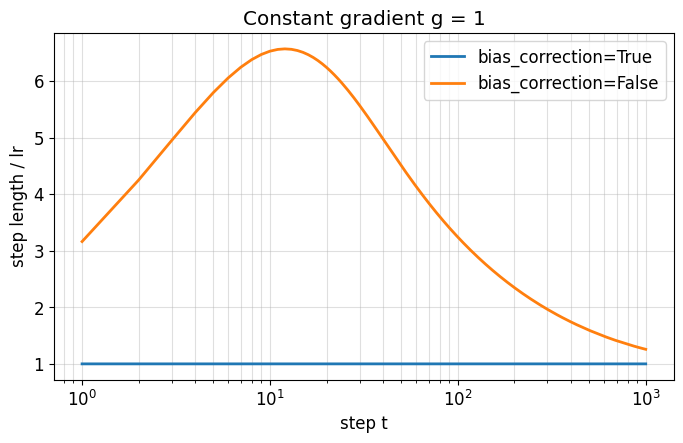

In [31]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ.** 

При g = 1 экспоненциальные средние равны $m_t = 1 - \beta_1^t$ и $v_t = 1 - \beta_2^t$, откуда длина шага без коррекции равна $\Delta = \mathrm{lr} \cdot (1 - \beta_1^t) / \sqrt{1 - \beta_2^t}$. Для $\beta_1 = 0.9$ и $\beta_2 = 0.999$ на t = 1 отношение $\mathrm{step} / \mathrm{lr}$ равно $0.1 / \sqrt{0.001} \approx 3.16$, затем достигает пика $6.57$ на $t = 12$ и асимптотически стремится к 1.00 к t = 1000, что в точности совпадает с выводом ячейки ($3.16 \to 6.53 \to 1.26$). Опасность: в начале обучения $v_t$ стартует с нуля и растёт медленнее $m_t$, из-за чего эффективный шаг на первых итерациях подскакивает в 6.5 раз; на неотлаженных начальных весах это приводит к дестабилизации оптимизации и взрыву градиентов. Ограничение: при наличии тёплого прогрева (warmup) или уже накопившихся статистик градиентов этот эффект сглаживается

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [32]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    ratio = min(1.0, step / total_steps)
    return min_ratio + (1.0 - min_ratio) * (1.0 + math.cos(math.pi * ratio)) / 2.0

In [33]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

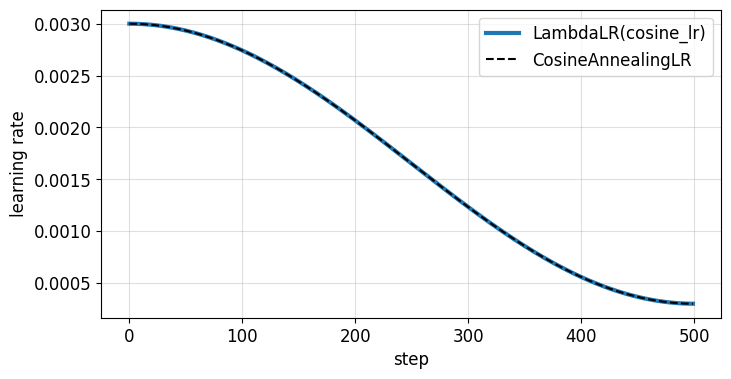

In [34]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ.** Адаптивность Adam нормирует шаги по отдельным координатам, но не устраняет стохастический шум, возникающий из-за оценки градиента по случайным мини-батчам. При постоянном learning rate стохастический метод не сходится в точный минимум, а совершает случайные блуждания по окрестности радиуса, пропорционального lr. Плавное снижение lr к концу обучения подавляет дисперсию градиентного шума, позволяя оптимизатору опуститься на дно локального минимума и стабилизировать финальные веса. Ограничение: слишком раннее зануление learning rate чревато преждевременной остановкой обучения в субоптимальной точке

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [35]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

100%|██████████| 170M/170M [11:09<00:00, 254kB/s]


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

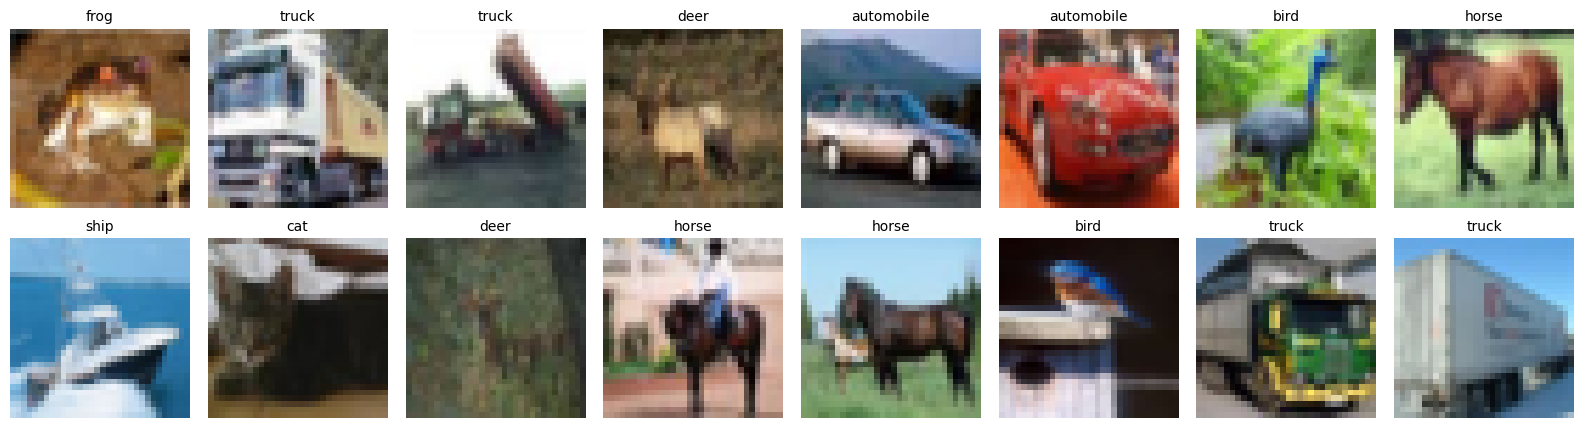

In [36]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [37]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(
            nn.Conv2d(c_in, c_in, kernel_size=3, stride=stride, padding=1, groups=c_in, bias=False),
            nn.Conv2d(c_in, c_out, kernel_size=1, stride=1, bias=False),
        )
    return nn.Conv2d(c_in, c_out, kernel_size=3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride=stride, separable=separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, stride=1, separable=separable)
        self.bn2 = nn.BatchNorm2d(c_out)

        if residual:
            if stride != 1 or c_in != c_out:
                self.shortcut = nn.Sequential(
                    nn.Conv2d(c_in, c_out, kernel_size=1, stride=stride, bias=False),
                    nn.BatchNorm2d(c_out),
                )
            else:
                self.shortcut = nn.Identity()
        else:
            self.shortcut = None

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6

        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(inplace=True),
        )

        stages = []
        c_in = widths[0]
        for stage_idx, c_out in enumerate(widths):
            for block_idx in range(n):
                stride = 2 if (stage_idx > 0 and block_idx == 0) else 1
                stages.append(Block(c_in, c_out, stride=stride, residual=residual, separable=separable))
                c_in = c_out
        self.stages = nn.Sequential(*stages)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], n_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.stages(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

In [38]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [ ]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()

    decay_params = [p for p in model.parameters() if p.requires_grad and p.ndim > 1]
    no_decay_params = [p for p in model.parameters() if p.requires_grad and p.ndim <= 1]
    param_groups = [
        {'params': decay_params, 'weight_decay': weight_decay},
        {'params': no_decay_params, 'weight_decay': 0.0},
    ]
    optimizer = MyAdamW(param_groups, lr=lr)

    steps_per_epoch = math.ceil(len(X_train) / batch_size)
    total_steps = epochs * steps_per_epoch
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=lambda step: cosine_lr(step, total_steps, min_ratio=0.0)
    )

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_samples = 0

        for x_batch, y_batch in iterate_batches(X_train, Y_train, batch_size=batch_size, shuffle=True, transform=normalize):
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = F.cross_entropy(logits, y_batch)
            loss.backward()
            optimizer.step()
            scheduler.step()

            total_loss += loss.item() * len(x_batch)
            total_samples += len(x_batch)

        epoch_loss = total_loss / total_samples
        history['train_loss'].append(epoch_loss)

        model.eval()
        test_logits = predict_logits(model, X_test, batch_size=1000, transform=normalize)
        current_test_acc = accuracy(test_logits, Y_test)
        history['test_acc'].append(current_test_acc)

        if log:
            elapsed = time.time() - start
            print(f'Epoch {epoch + 1:2d}/{epochs:2d} [{elapsed:5.1f}s]: '
                  f'train loss = {epoch_loss:.4f}, test acc = {current_test_acc:.4f}')

    return history

In [40]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

Epoch  1/20 [ 17.8s]: train loss = 1.4300, test acc = 0.5688
Epoch  2/20 [ 33.2s]: train loss = 0.9461, test acc = 0.6246
Epoch  3/20 [ 48.9s]: train loss = 0.7495, test acc = 0.6961
Epoch  4/20 [ 64.7s]: train loss = 0.6359, test acc = 0.6576
Epoch  5/20 [ 80.8s]: train loss = 0.5588, test acc = 0.7585
Epoch  6/20 [ 97.2s]: train loss = 0.4867, test acc = 0.7553
Epoch  7/20 [113.9s]: train loss = 0.4182, test acc = 0.7479
Epoch  8/20 [130.9s]: train loss = 0.3655, test acc = 0.7833
Epoch  9/20 [148.1s]: train loss = 0.3124, test acc = 0.7704
Epoch 10/20 [165.3s]: train loss = 0.2608, test acc = 0.8016
Epoch 11/20 [182.2s]: train loss = 0.2032, test acc = 0.7910
Epoch 12/20 [199.1s]: train loss = 0.1506, test acc = 0.8110
Epoch 13/20 [216.0s]: train loss = 0.1060, test acc = 0.8102
Epoch 14/20 [233.1s]: train loss = 0.0654, test acc = 0.8258
Epoch 15/20 [250.2s]: train loss = 0.0380, test acc = 0.8307
Epoch 16/20 [267.2s]: train loss = 0.0228, test acc = 0.8312
Epoch 17/20 [284.2s]: tr

{'train acc': 0.9996999502182007, 'test acc': 0.8303999900817871}

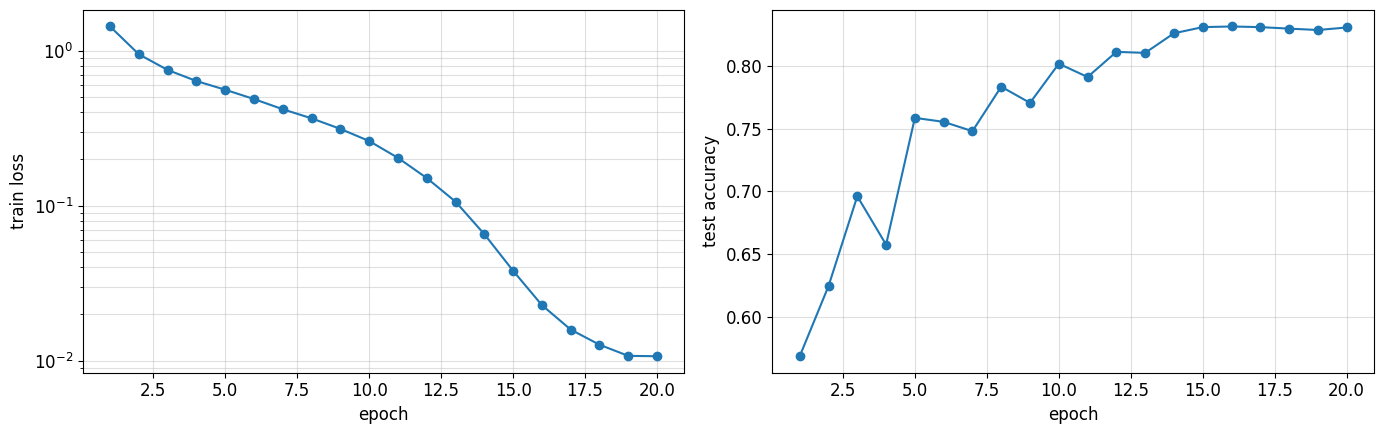

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ.** В конце 20-й эпохи разрыв между train и test accuracy составил около 16.9 процентных пунктов: train acc достигла 99.97%, а test acc - 83.04%. На последних эпохах (15-20), по мере ухода learning rate к нулю, train loss продолжал монотонно снижаться до плато 0.0107, в то время как test accuracy вышла в насыщение и колебалась в узком диапазоне 82.8%-83.1% без заметного переобучения. Такой разрыв закономерен, поскольку в протоколе отсутствуют аугментации данных, позволяя сети почти идеально запомнить обучающую выборку. Ограничение: добавление случайных аугментаций (RandomCrop, Flip) сократило бы этот разрыв и повысило обобщающую способность на тесте

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [42]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [43]:
ablation = {}

for name, config in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**config)
    params = n_params(model)

    start_time = time.perf_counter()
    history = train_cifar(model, ABL_EPOCHS, LR)
    minutes = (time.perf_counter() - start_time) / 60.0

    train_acc = accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000])
    test_acc = history['test_acc'][-1]

    ablation[name] = dict(
        params=params,
        train_acc=train_acc,
        test_acc=test_acc,
        minutes=minutes,
        history=history,
    )

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

Epoch  1/10 [ 16.2s]: train loss = 1.7122, test acc = 0.3777
Epoch  2/10 [ 32.4s]: train loss = 1.3425, test acc = 0.5420
Epoch  3/10 [ 48.6s]: train loss = 1.0856, test acc = 0.6089
Epoch  4/10 [ 64.8s]: train loss = 0.9167, test acc = 0.6554
Epoch  5/10 [ 81.0s]: train loss = 0.7869, test acc = 0.7085
Epoch  6/10 [ 97.3s]: train loss = 0.6857, test acc = 0.7358
Epoch  7/10 [113.5s]: train loss = 0.5976, test acc = 0.7521
Epoch  8/10 [129.7s]: train loss = 0.5270, test acc = 0.7789
Epoch  9/10 [146.0s]: train loss = 0.4739, test acc = 0.7889
Epoch 10/10 [162.3s]: train loss = 0.4471, test acc = 0.7872
Epoch  1/10 [ 48.7s]: train loss = 1.9738, test acc = 0.2343
Epoch  2/10 [ 97.4s]: train loss = 1.8448, test acc = 0.2915
Epoch  3/10 [146.1s]: train loss = 1.7275, test acc = 0.3445
Epoch  4/10 [194.9s]: train loss = 1.6225, test acc = 0.3744
Epoch  5/10 [243.7s]: train loss = 1.5588, test acc = 0.3727
Epoch  6/10 [292.5s]: train loss = 1.4661, test acc = 0.4556
Epoch  7/10 [341.3s]: tr

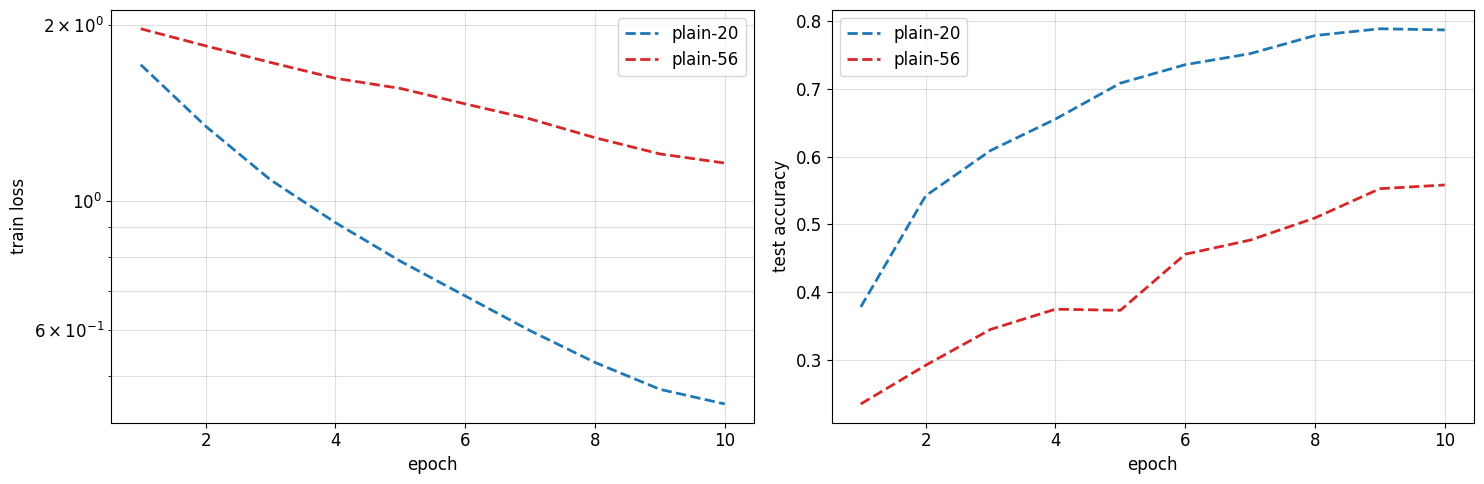

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ.** 

Да, в прогоне зафиксировано резкое ухудшение на train: при увеличении глубины plain-сети с 20 до 56 слоёв финальный train loss вырос с 0.4471 до 1.1600. При этом train accuracy обвалилась с 85.70% до 58.03% (-27.67 п.п.), а test accuracy упала с 78.72% до 55.80% (-22.92 п.п.)


О трудностях оптимизации (проблеме деградации) однозначно свидетельствует падение качества на обучающей выборке: модель с 853k параметров имеет заведомо большую ёмкость, чем модель с 270k, но не может даже сойтись на train из-за затухания градиентов без shortcut-связей. Если бы имело место переобучение, train loss был бы около нуля, а падала бы только test accuracy


Контрольный эксперимент: обучить ResNet-56 (с идентичными весами и протоколом на 10 эпох, но с включёнными residual-связями); если гипотеза о проблеме оптимизации верна, наличие shortcut-соединений позволит ResNet-56 достичь train loss существенно ниже, чем у plain-56 и plain-20

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [45]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.85MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 17.2MB/s]


(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [46]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [47]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [48]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.918, 'FGSM, eps=0.1': 0.067, 'PGD-20, eps=0.1': 0.005}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [ ]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()
    view_shape = (-1,) + (1,) * (x.ndim - 1)

    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            loss = F.cross_entropy(model(x_adv), y)
            grad, = torch.autograd.grad(loss, x_adv)

        g_norm = grad.flatten(1).norm(p=2, dim=1).clamp_min(1e-12).view(view_shape)
        x_prime = x_adv.detach() + alpha * (grad / g_norm)

        delta = x_prime - x
        d_norm = delta.flatten(1).norm(p=2, dim=1).clamp_min(1e-12).view(view_shape)
        factor = torch.clamp(eps / d_norm, max=1.0)

        x_adv = torch.clamp(x + delta * factor, 0.0, 1.0)

    return x_adv.detach()

In [50]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.922; маленькое падение требует диагностики.


(0.922, 0.0)

In [51]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.918, 0.5: 0.444, 1.0: 0.08, 1.5: 0.012, 2.0: 0.0, 3.0: 0.0, 4.0: 0.0},
 0.005)

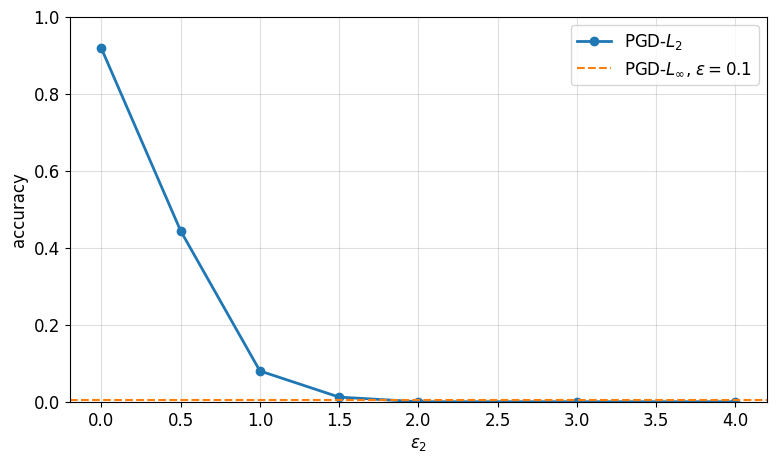

In [52]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=2.0, accuracy gap=0.005


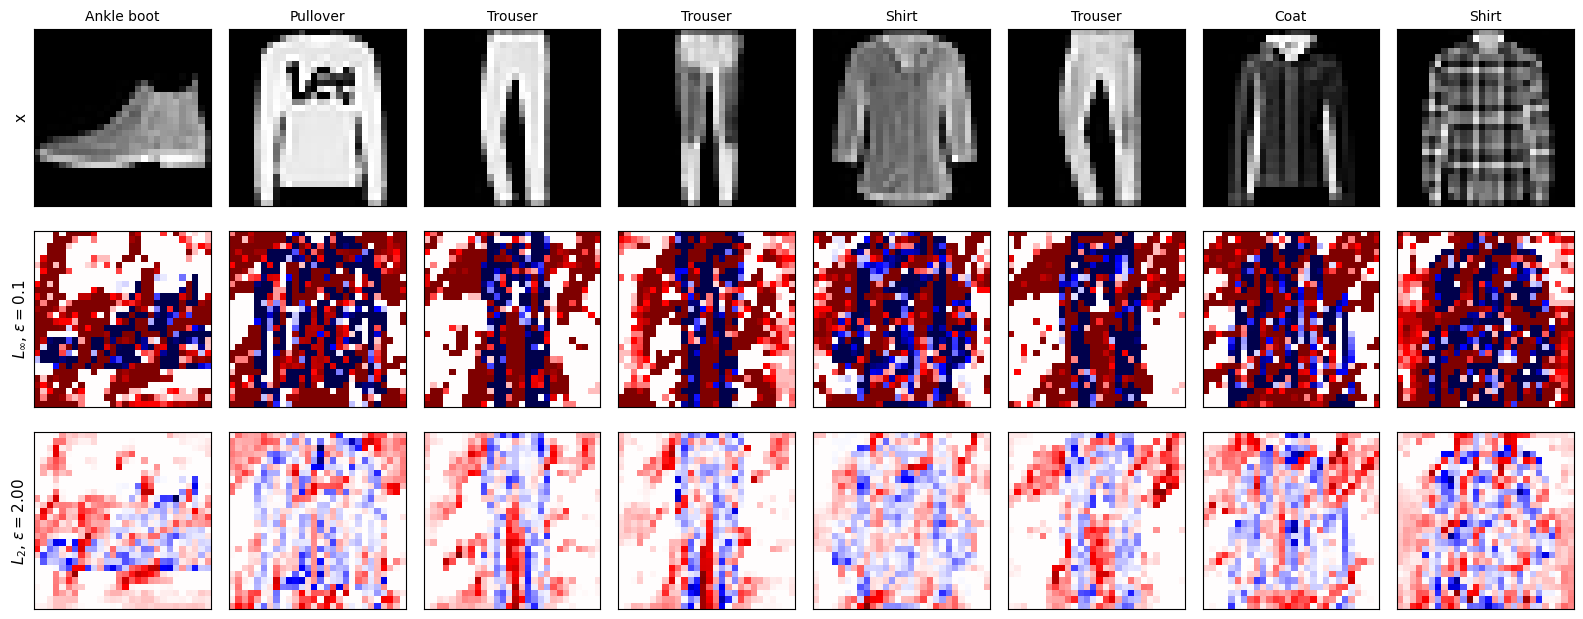

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.098
$L_2$, $\varepsilon=2.00$    L_inf = 0.348   L_2 = 1.987


In [ ]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.** Ближайшей точкой сетки оказалась eps2 = 2.0 с точностью 0.0% и остаточным разрывом всего 0.005 относительно L_inf (где accuracy составила 0.005). Средняя L_2-норма самого L_inf-возмущения составила 2.098, что практически совпадает с радиусом сферы eps2 = 2.00 (у которой L_2 = 1.987). В отличие от L_inf-атаки, где операция sign(g) равномерно зашумляет всю картинку, L_2-возмущение локализовано строго на контурах и деталях силуэта одежды, оставляя фон чистым. Это объясняется шагом по нормированному градиенту g / ||g||_2: на однородном фоне производные loss близки к нулю, поэтому почти весь бюджет нормы расходуется на области с высокой крутизной градиента (где локальный всплеск достигает L_inf = 0.348). Ограничение: близость по accuracy между L_inf (0.1) и L_2 (2.0) зафиксирована для конкретного бюджета в 20 шагов PGD

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [ ]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        target = target.to(x.device)
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                loss = F.cross_entropy(model(x_adv), target)
                grad, = torch.autograd.grad(loss, x_adv)
            x_adv = x_adv.detach() - alpha * grad.sign()
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        alpha = 2.5 * eps / steps
        S = torch.full((n_classes, n_classes), float('nan'), dtype=torch.float32)
        batch_size = 128
        for s in range(n_classes):
            mask = (y == s)
            n_s = mask.sum().item()
            if n_s == 0:
                continue
            x_s = x[mask]
            for t in range(n_classes):
                if s == t:
                    continue
                successful = 0
                for i in range(0, n_s, batch_size):
                    batch_x = x_s[i:i + batch_size]
                    batch_t = torch.full((len(batch_x),), t, dtype=torch.long, device=batch_x.device)
                    x_adv = pgd_targeted(model, batch_x, batch_t, eps=eps, alpha=alpha, steps=steps)
                    with torch.no_grad():
                        preds = model(x_adv).argmax(dim=1)
                        successful += (preds == batch_t).sum().item()
                S[s, t] = successful / n_s
        return S

In [55]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.765; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.93 0.   0.01 0.03 0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.05 0.   0.01 0.88 0.03 0.   0.02 0.   0.   0.  ]
 [0.   0.   0.06 0.03 0.89 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.98 0.   0.01 0.   0.01]
 [0.09 0.   0.06 0.03 0.06 0.   0.75 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.   0.   0.   0.   0.   0.   0.01 0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


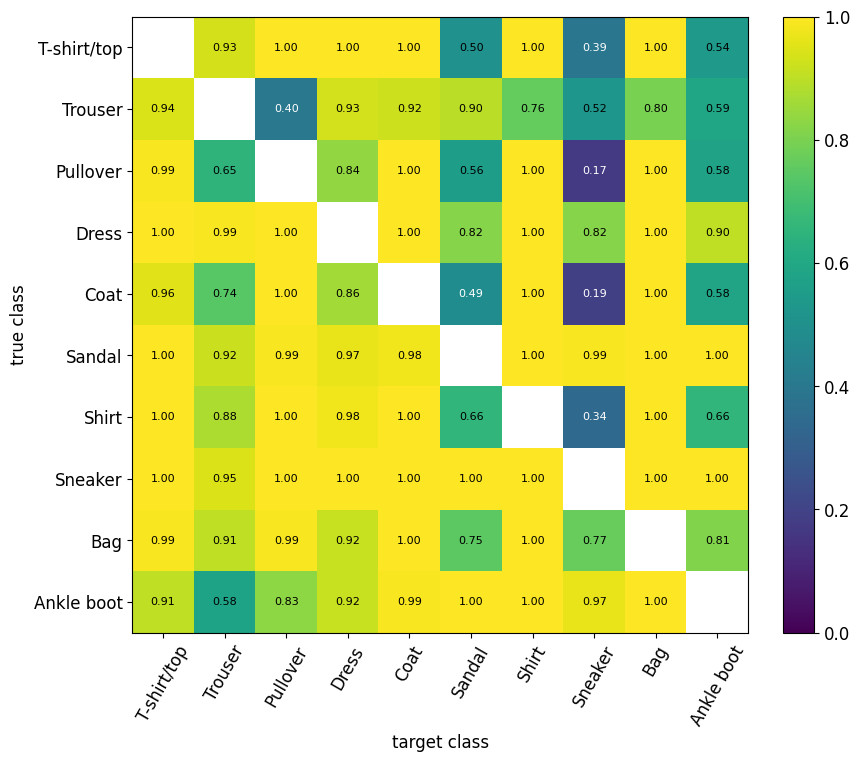

In [56]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** Легче всего (успешность 1.00) атакуются взаимные пары категорий одежды: например, T-shirt в Pullover, Dress или Coat, а также Sneaker в другие классы. Труднее всего превратить верхнюю одежду в обувь: Pullover -> Sneaker (успешность 0.17) и Coat -> Sneaker (0.19). Матрица успеха явно несимметрична: например, атака Sneaker -> Coat успешна в 100% случаев, тогда как обратная Coat -> Sneaker срабатывает лишь в 19% случаев. Это напрямую согласуется с чистой матрицей ошибок (clean confusion): без атак модель путает только близкие вещи одной группы (Shirt путается с T-shirt в 9% и с Coat в 6%), тогда как ошибки между одеждой и обувью равны строго 0.00. Семантически далекие классы разделены широким маржином классификатора, который при бюджете eps = 0.1 преодолеть сложнее всего

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [57]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.**

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [58]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [ ]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval()
            x_adv = attack(model, x, y, eps).detach()

            model.train()
            optimizer.zero_grad()
            out = model(x_adv)
            loss = F.cross_entropy(out, y)
            loss.backward()
            optimizer.step()

        test_x = XF_test[:1000]
        test_y = YF_test[:1000]
        acc_clean = attack_accuracy(model, test_x, test_y)
        acc_fgsm = attack_accuracy(model, test_x, test_y, fgsm_attack, eps=eps)
        acc_pgd = attack_accuracy(model, test_x, test_y, pgd, eps=eps)

        history['clean'].append(acc_clean)
        history['fgsm'].append(acc_fgsm)
        history['pgd'].append(acc_pgd)

        if log:
            print(f"Epoch {epoch + 1:2d}/{epochs:2d} | Clean: {acc_clean:.4f} | FGSM: {acc_fgsm:.4f} | PGD-20: {acc_pgd:.4f}")

    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [60]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
Epoch  1/ 5 | Clean: 0.8060 | FGSM: 0.7000 | PGD-20: 0.6640
Epoch  2/ 5 | Clean: 0.8230 | FGSM: 0.7030 | PGD-20: 0.6640
Epoch  3/ 5 | Clean: 0.8210 | FGSM: 0.7240 | PGD-20: 0.7000
Epoch  4/ 5 | Clean: 0.8360 | FGSM: 0.7190 | PGD-20: 0.6970
Epoch  5/ 5 | Clean: 0.8420 | FGSM: 0.7480 | PGD-20: 0.7160


In [61]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.918   0.123   0.006   0.000   0.000   0.000
PGD-AT       0.842   0.791   0.720   0.473   0.135   0.001


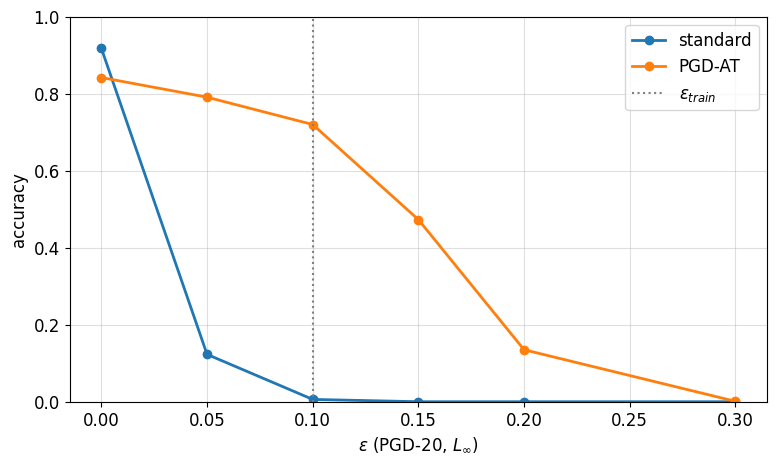

In [62]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.** Плата за робастность составила 7.6 процентных пунктов clean accuracy: точность чистой модели упала с 91.8% до 84.2%. При выходе за радиус обучения (eps > 0.10) устойчивость модели стремительно деградирует: с 72.0% при eps=0.10 точность падает до 47.3% при eps=0.15 и обнуляется (0.1%) при eps=0.30, демонстрируя локальный характер защиты. По числу проходов PGD-7 дороже стандартного обучения ровно в 8 раз: на каждый батч генерация состязательного примера требует 7 forward и 7 backward по входу, плюс финальный шаг по весам (1 forward + 1 backward); по реальному времени обучение PGD-AT заняло 46.0 с против 7.5 с у стандартного (в 6.1 раз дольше)

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def sanity_checks(model, x, y, eps):
    model.eval()
    batch_size = 128
    n_samples = len(x)

    fgsm_correct_cnt = 0
    pgd20_correct_cnt = 0
    pgd100_x5_correct_cnt = 0
    eps_1_correct_cnt = 0

    for i in range(0, n_samples, batch_size):
        xb = x[i:i + batch_size]
        yb = y[i:i + batch_size]

        with torch.no_grad():
            clean_correct = (model(xb).argmax(dim=1) == yb)

        xb_fgsm = fgsm_attack(model, xb, yb, eps)
        with torch.no_grad():
            fgsm_correct = clean_correct & (model(xb_fgsm).argmax(dim=1) == yb)
        fgsm_correct_cnt += fgsm_correct.sum().item()

        xb_pgd20 = pgd(model, xb, yb, eps=eps, steps=20)
        with torch.no_grad():
            pgd20_correct = clean_correct & (model(xb_pgd20).argmax(dim=1) == yb)
        pgd20_correct_cnt += pgd20_correct.sum().item()

        pgd100_mask = clean_correct.clone()
        for _ in range(5):
            xb_pgd100 = pgd(model, xb, yb, eps=eps, steps=100)
            with torch.no_grad():
                pgd100_mask = pgd100_mask & (model(xb_pgd100).argmax(dim=1) == yb)
        pgd100_x5_correct_cnt += pgd100_mask.sum().item()

        xb_eps1 = pgd(model, xb, yb, eps=1.0, steps=20)
        with torch.no_grad():
            eps_1_correct = clean_correct & (model(xb_eps1).argmax(dim=1) == yb)
        eps_1_correct_cnt += eps_1_correct.sum().item()

    return {
        'fgsm': fgsm_correct_cnt / n_samples,
        'pgd20': pgd20_correct_cnt / n_samples,
        'pgd100_x5': pgd100_x5_correct_cnt / n_samples,
        'eps_1': eps_1_correct_cnt / n_samples,
    }

In [64]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.078      0.012      0.008      0.000
PGD-AT                      0.746      0.727      0.719      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.** При усилении атаки accuracy модели PGD-AT снижается плавно: с 74.6% на FGSM до 72.7% на PGD-20 и 71.9% на PGD-100 с 5 рестартами, а при eps=1.0 строго зануляется (0.0%). Подозрительных аномалий нет: точность монотонно убывает с ростом силы атаки, а нулевой результат при eps=1.0 подтверждает отсутствие тривиальной маскировки градиентов (gradient masking); дополнительно можно провести безградиентную атаку (Square Attack / AutoAttack). Модель с высокой FGSM и нулевой PGD accuracy пройти эти проверки не сможет, так как проверка pgd100_x5 сразу покажет около 0%. Такой разрыв свидетельствует об эффекте маскировки градиента или catastrophic overfitting - одношаговый градиент становится бесполезным, но многошаговая атака легко ломает сеть, поэтому реальной робастностью модель не обладает

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def input_gradient(model, x, y):
    orig_dtype = x.dtype
    x_double = x.detach().clone().double().requires_grad_(True)

    model.double()
    with torch.enable_grad():
        logits = model(x_double)
        zy = logits.gather(1, y.unsqueeze(1)).sum()
        grad, = torch.autograd.grad(zy, x_double)

    model.float()
    return grad.abs().to(orig_dtype)


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [69]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs(), rtol=1e-4, atol=1e-4)

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5972944498062134, 'PGD-AT': 0.22340522706508636}

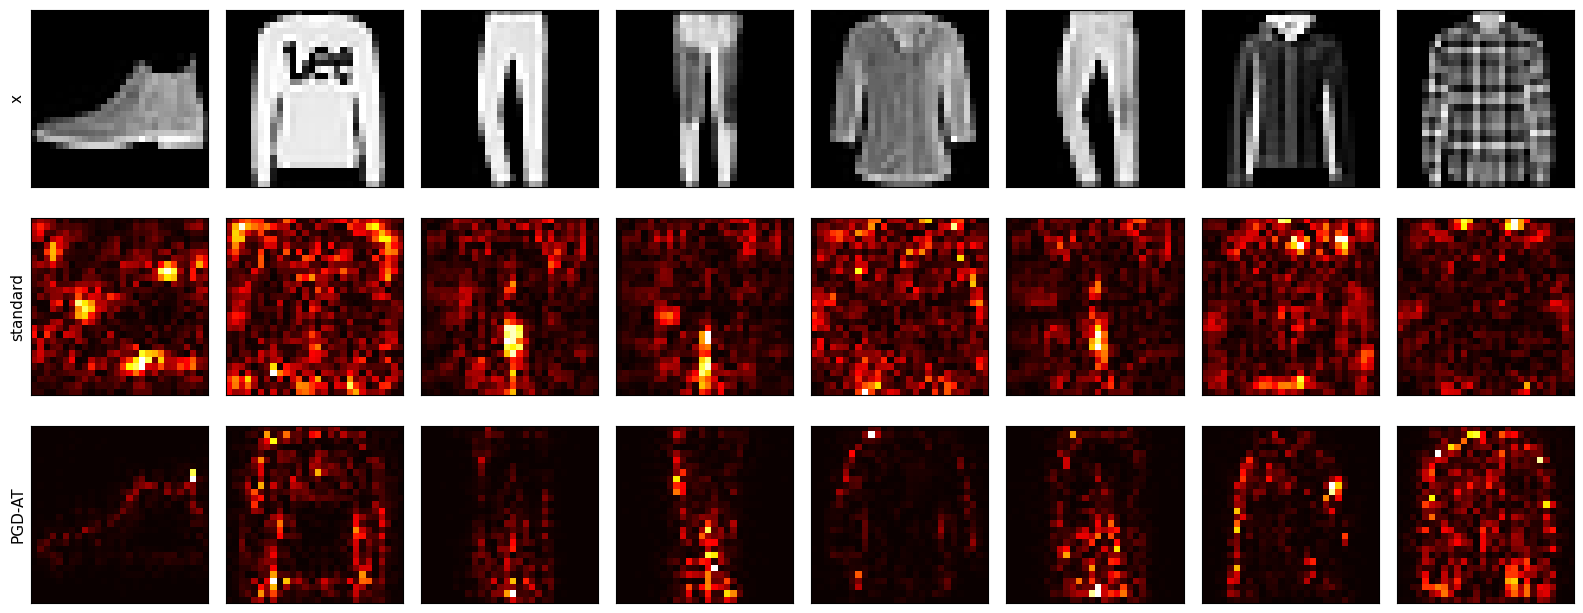

In [70]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.** У стандартной модели градиент визуально выглядит как высокочастотный шум, размазанный по фону (на фон приходится 59.7% массы градиента при доле фона 49.8%). У PGD-AT модели карта сфокусирована строго на контурах одежды, а доля массы на фоне падает до 22.3% (в 2.7 раза меньше). Это напрямую согласуется с PGD-точностью моделей (72.0% у PGD-AT против 0.6% у стандартной): устойчивая сеть опирается на реальные силуэтные признаки объекта, а не на нерелевантные пиксели фона. Однако красивой saliency-карты недостаточно: локальная гладкость градиента может быть следствием сглаживания или скрытого затухания градиентов, и только прямое тестирование сильными адаптивными атаками подтверждает устойчивость

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [71]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [ ]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        return torch.autograd.grad(grads, params, grad_outputs=v, retain_graph=True)


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [73]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [74]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

Training with eta = 0.05 (2/eta = 40.0)...
Training with eta = 0.1 (2/eta = 20.0)...
Training with eta = 0.2 (2/eta = 10.0)...


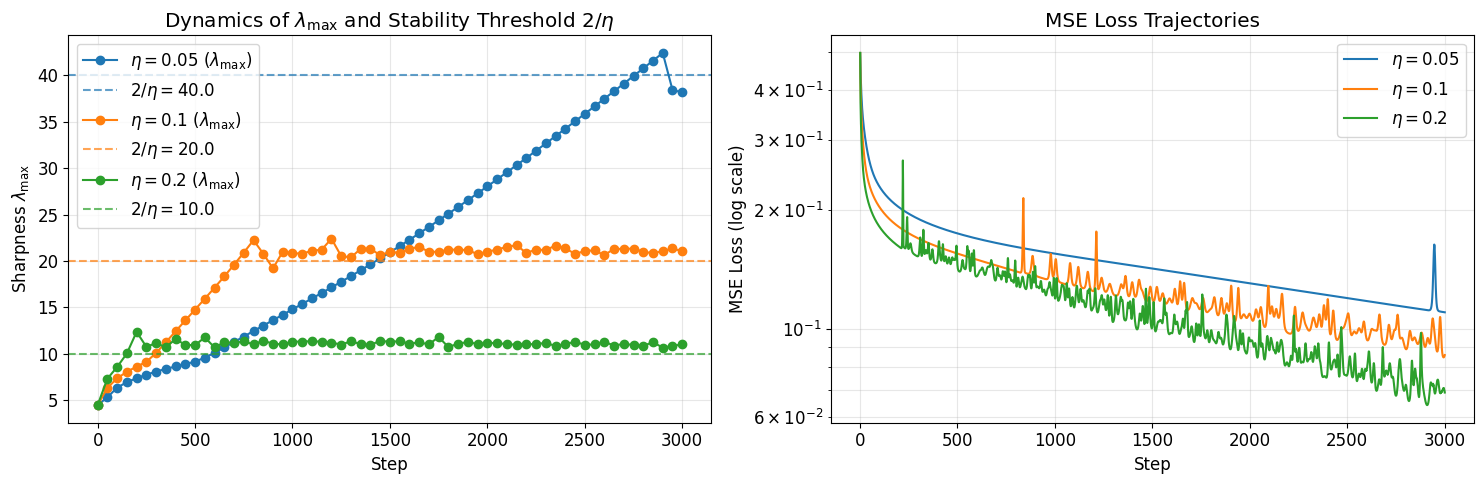

In [ ]:
if '7.1' in BONUS_TASKS:
    etas = [0.05, 0.1, 0.2]
    eos_results = {}

    for eta in etas:
        print(f'Training with eta = {eta} (2/eta = {2/eta:.1f})...')
        model = make_tanh_mlp(seed=0)
        optimizer = torch.optim.SGD(model.parameters(), lr=eta)

        loss_history = []
        lambda_history = []
        eval_steps = []
        v_warm = None

        for step in range(EOS_STEPS + 1):
            if step % 50 == 0:
                lam, v_warm = top_eigenvalue(lambda: mse_loss(model), list(model.parameters()), iters=20, v=v_warm)
                lambda_history.append(lam)
                eval_steps.append(step)

            if step < EOS_STEPS:
                optimizer.zero_grad()
                loss = mse_loss(model)
                loss_history.append(loss.item())
                loss.backward()
                optimizer.step()

        eos_results[eta] = {
            'loss': loss_history,
            'lambda': lambda_history,
            'steps': eval_steps
        }

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for (eta, res), color in zip(eos_results.items(), colors):
        threshold = 2.0 / eta
        ax1.plot(res['steps'], res['lambda'], 'o-', color=color, label=f'$\\eta={eta}$ ($\\lambda_{{\\max}}$)')
        ax1.axhline(threshold, linestyle='--', color=color, alpha=0.7, label=f'$2/\\eta={threshold:.1f}$')

        ax2.semilogy(range(1, len(res['loss']) + 1), res['loss'], color=color, label=f'$\\eta={eta}$')

    ax1.set_xlabel('Step')
    ax1.set_ylabel(r'Sharpness $\lambda_{\max}$')
    ax1.set_title(r'Dynamics of $\lambda_{\max}$ and Stability Threshold $2/\eta$')
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    ax2.set_xlabel('Step')
    ax2.set_ylabel('MSE Loss (log scale)')
    ax2.set_title('MSE Loss Trajectories')
    ax2.grid(True, which='both', alpha=0.3)
    ax2.legend()

    plt.tight_layout()
    plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** Sharpness вышла на границу 2 / eta и стабилизировалась вдоль неё при eta = 0.2 (порог 10) и eta = 0.1 (порог 20); при eta = 0.05 выхода на порог 40 за 3000 шагов не было. С выходом на границу монотонное убывание loss сменяется локальными микроосцилляциями, но в среднем оптимизатор продолжает сходиться вдоль границы устойчивости. В отличие от квадратичной функции, где шаг при eta > 2 / lambda_max вызывает экспоненциальный взрыв, в нелинейной сети большой шаг отбрасывает параметры в более пологую область ландшафта (эффект самостабилизации). Ограничение: при чересчур больших eta сеть может разойтись на первых итерациях ещё до входа в режим самостабилизации

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [ ]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        sh, sw = pair(stride)
        ph, pw = pair(padding)

        if ph > 0 or pw > 0:
            x = F.pad(x, (pw, pw, ph, ph))

        B, C_in, H, W = x.shape
        C_out, C_in_g, kh, kw = weight.shape
        assert C_in == groups * C_in_g, f"C_in ({C_in}) != groups ({groups}) * in_channels_per_group ({C_in_g})"
        cout_g = C_out // groups

        x_g = x.view(B, groups, C_in_g, H, W)
        w_g = weight.flip(-2, -1).view(groups, cout_g, C_in_g, kh, kw)

        fft_size = (H + kh - 1, W + kw - 1)
        X = torch.fft.rfft2(x_g, s=fft_size)
        W_fft = torch.fft.rfft2(w_g, s=fft_size)

        Y = torch.einsum('bgchw,gochw->bgohw', X, W_fft)
        y_full = torch.fft.irfft2(Y, s=fft_size)

        y_valid = y_full[..., kh - 1:H, kw - 1:W]
        out = y_valid.flatten(1, 2)[..., ::sh, ::sw]

        if bias is not None:
            out = out + bias.view(1, -1, 1, 1)

        return out

In [77]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.** Свёртка через БПФ всегда считает полный выход со stride 1, поэтому при шаге s сохраняется лишь 1 из s^2 значений, а выбрасывается доля (s^2 - 1) / s^2 (при s = 2 отбрасывается 75% вычислений, при s = 3 — 88.9%). FFT-свёртка остаётся выгоднее прямой при больших ядрах (от 7x7) и малом s, так как её сложность O(HW log(HW)) не зависит от размера ядра k, что перевешивает потери на прореживание. Ограничение: на ядрах 3x3 или при больших шагах (s >= 2) накладные расходы Фурье делают FFT заведомо медленнее im2col

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [78]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        a, b, c = coeffs
        orig_shape = M.shape
        if M.ndim > 2:
            M = M.flatten(1)
        X = M / (M.norm() + 1e-7)
        transposed = X.shape[0] > X.shape[1]
        if transposed:
            X = X.T
        for _ in range(steps):
            A = X @ X.T
            X = a * X + (b * A + c * A @ A) @ X
        if transposed:
            X = X.T
        return X.view(orig_shape)


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                lr = group['lr']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    g = p.grad
                    state = self.state[p]
                    if 'momentum_buffer' not in state:
                        state['momentum_buffer'] = torch.zeros_like(p)
                    buf = state['momentum_buffer']
                    buf.mul_(mu).add_(g, alpha=1 - mu)
                    u = (1 - mu) * g + mu * buf

                    m = p.shape[0]
                    n = p.numel() // m
                    scale = (max(1.0, m / n)) ** 0.5

                    update = newton_schulz(u)
                    p.add_(update, alpha=-lr * scale)

In [79]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [ ]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02

    set_seed(0)
    model_muon = ResNetCIFAR(20).to(device)

    conv_params = [p for p in model_muon.parameters() if p.requires_grad and p.ndim == 4]

    other_decay = [p for p in model_muon.parameters() if p.requires_grad and p.ndim != 4 and p.ndim > 1]
    other_no_decay = [p for p in model_muon.parameters() if p.requires_grad and p.ndim != 4 and p.ndim <= 1]

    opt_muon = ConvMuon(conv_params, lr=MUON_LR)
    opt_adam = MyAdamW([
        {'params': other_decay, 'weight_decay': 0.05},
        {'params': other_no_decay, 'weight_decay': 0.0},
    ], lr=LR)

    batch_size = 256
    steps_per_epoch = math.ceil(len(X_train) / batch_size)
    total_steps = EPOCHS * steps_per_epoch

    sched_muon = torch.optim.lr_scheduler.LambdaLR(
        opt_muon, lr_lambda=lambda step: cosine_lr(step, total_steps, min_ratio=0.0)
    )
    sched_adam = torch.optim.lr_scheduler.LambdaLR(
        opt_adam, lr_lambda=lambda step: cosine_lr(step, total_steps, min_ratio=0.0)
    )

    hist_muon = dict(train_loss=[], test_acc=[])
    start = time.time()

    for epoch in range(EPOCHS):
        model_muon.train()
        total_loss = 0.0
        total_samples = 0

        for x_batch, y_batch in iterate_batches(X_train, Y_train, batch_size=batch_size, shuffle=True, transform=normalize):
            opt_muon.zero_grad()
            opt_adam.zero_grad()

            logits = model_muon(x_batch)
            loss = F.cross_entropy(logits, y_batch)
            loss.backward()

            opt_muon.step()
            opt_adam.step()
            sched_muon.step()
            sched_adam.step()

            total_loss += loss.item() * len(x_batch)
            total_samples += len(x_batch)

        epoch_loss = total_loss / total_samples
        hist_muon['train_loss'].append(epoch_loss)

        model_muon.eval()
        test_logits = predict_logits(model_muon, X_test, batch_size=1000, transform=normalize)
        current_test_acc = accuracy(test_logits, Y_test)
        hist_muon['test_acc'].append(current_test_acc)

        elapsed = time.time() - start
        print(f'Epoch {epoch + 1:2d}/{EPOCHS:2d} [{elapsed:5.1f}s]: '
              f'train loss = {epoch_loss:.4f}, test acc = {current_test_acc:.4f}')

    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

Epoch  1/20 [ 18.0s]: train loss = 1.1526, test acc = 0.6558
Epoch  2/20 [ 36.0s]: train loss = 0.6763, test acc = 0.7741
Epoch  3/20 [ 53.7s]: train loss = 0.5093, test acc = 0.7490
Epoch  4/20 [ 71.2s]: train loss = 0.4031, test acc = 0.8144
Epoch  5/20 [ 88.7s]: train loss = 0.3226, test acc = 0.8114
Epoch  6/20 [106.4s]: train loss = 0.2433, test acc = 0.8279
Epoch  7/20 [124.1s]: train loss = 0.1827, test acc = 0.8300
Epoch  8/20 [141.8s]: train loss = 0.1333, test acc = 0.8297
Epoch  9/20 [159.5s]: train loss = 0.0936, test acc = 0.8279
Epoch 10/20 [177.1s]: train loss = 0.0640, test acc = 0.8321
Epoch 11/20 [194.7s]: train loss = 0.0424, test acc = 0.8373
Epoch 12/20 [212.3s]: train loss = 0.0280, test acc = 0.8373
Epoch 13/20 [229.9s]: train loss = 0.0176, test acc = 0.8440
Epoch 14/20 [247.4s]: train loss = 0.0104, test acc = 0.8360
Epoch 15/20 [265.1s]: train loss = 0.0058, test acc = 0.8415
Epoch 16/20 [282.7s]: train loss = 0.0033, test acc = 0.8419
Epoch 17/20 [300.3s]: tr

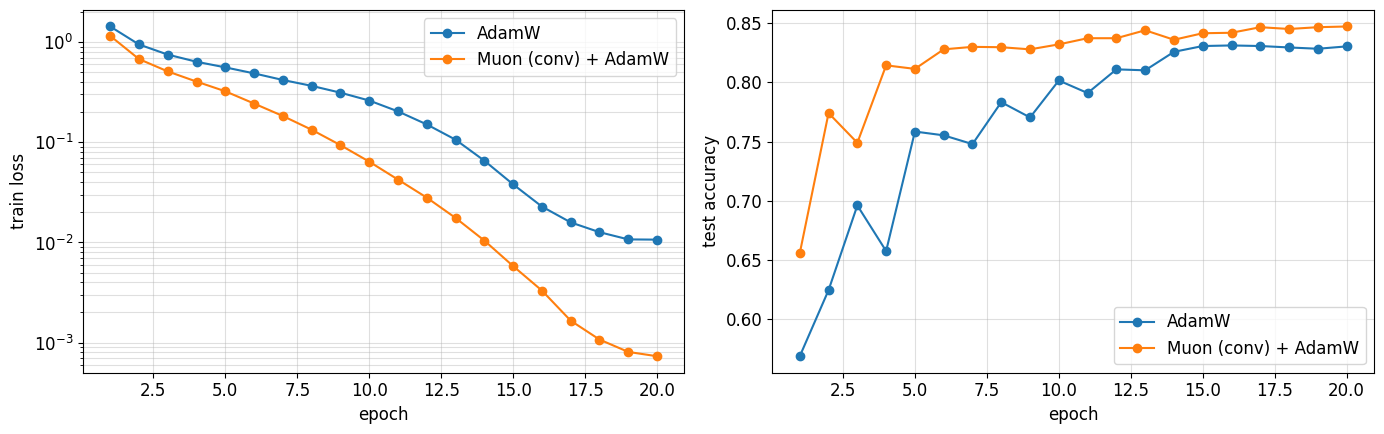

In [81]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** Muon быстрее и глубже снижает train loss (к 20-й эпохе 0.0007 против 0.0107 у AdamW) и даёт лучшую test accuracy (84.72% против 83.04% у AdamW). AdamW требует 8 байт на параметр (два float32-момента: exp_avg и exp_avg_sq), тогда как Muon хранит только один буфер импульса (4 байта на параметр), экономя память оптимизатора в 2 раза. Ограничение: Muon применим только к многомерным матрицам и свёрткам, а 1D-параметры (вектора смещений и BatchNorm) требуют отдельного классического оптимизатора

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [82]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [83]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.922, 'L0, k=5': 0.668}
standard    0.922  0.892  0.856  0.786  0.668  0.390  0.126  0.022
PGD-AT      0.854  0.820  0.784  0.764  0.714  0.624  0.408  0.290


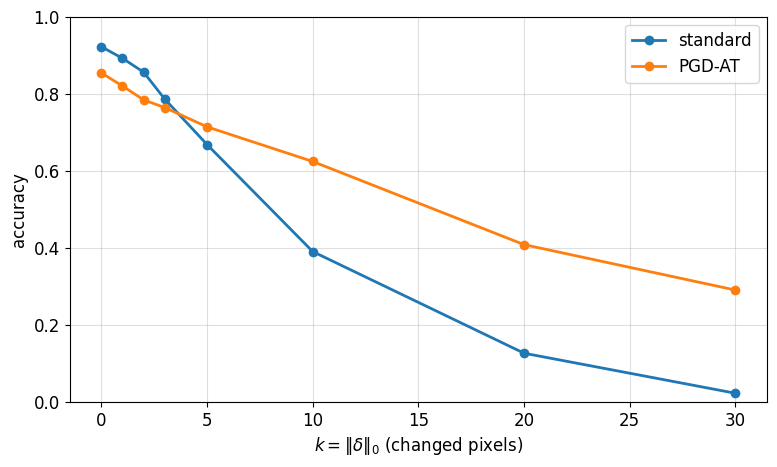

In [84]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.** L_inf-робастность заметно помогает против L_0-атаки: модель PGD-AT удерживает 71.4% accuracy при k = 5 изменённых пикселях (против 66.8% у стандартной) и 29.0% при k = 50 (против 2.2%). При этом L_inf-шар не спасает от изменения одного пикселя с 0 до 1, так как амплитуда |1 - 0| = 1.0 в десять раз превышает защитный радиус обучения eps = 0.1. Ограничение: перенос устойчивости носит сугубо эмпирический характер благодаря сглаживанию признаков, но строгих теоретических гарантий в метрике L_0 не даёт

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [85]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
Epoch  1/ 5 | Clean: 0.7340 | FGSM: 0.6210 | PGD-20: 0.0560
Epoch  2/ 5 | Clean: 0.6010 | FGSM: 0.8770 | PGD-20: 0.0010
Epoch  3/ 5 | Clean: 0.5230 | FGSM: 0.9360 | PGD-20: 0.0010
Epoch  4/ 5 | Clean: 0.5620 | FGSM: 0.9660 | PGD-20: 0.0010
Epoch  5/ 5 | Clean: 0.5390 | FGSM: 0.9850 | PGD-20: 0.0000
FGSM-RS
Epoch  1/ 5 | Clean: 0.7700 | FGSM: 0.6190 | PGD-20: 0.3730
Epoch  2/ 5 | Clean: 0.7910 | FGSM: 0.6510 | PGD-20: 0.3940
Epoch  3/ 5 | Clean: 0.7950 | FGSM: 0.7120 | PGD-20: 0.4220
Epoch  4/ 5 | Clean: 0.8030 | FGSM: 0.7030 | PGD-20: 0.4400
Epoch  5/ 5 | Clean: 0.8130 | FGSM: 0.7450 | PGD-20: 0.4100


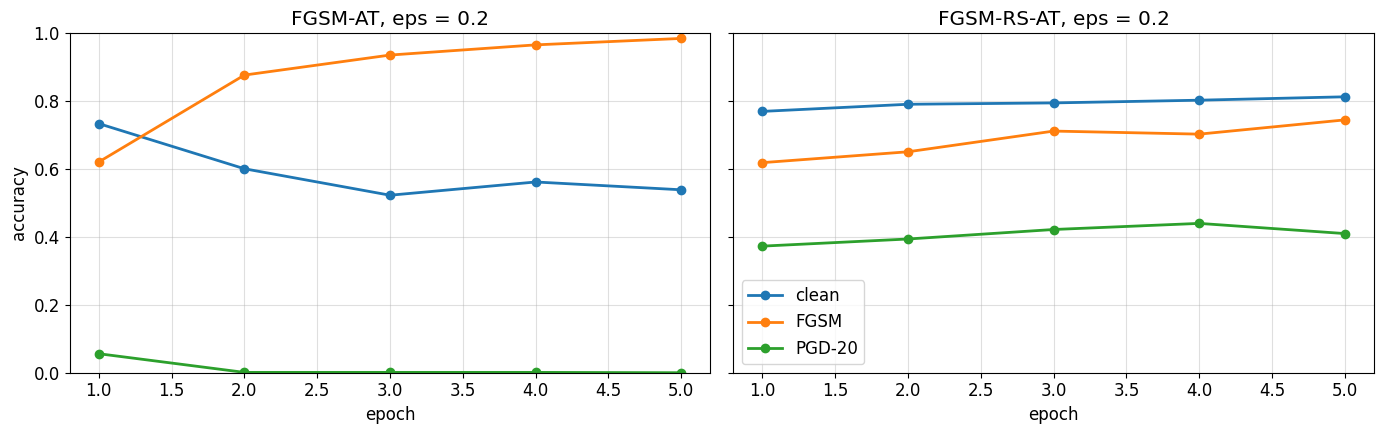

In [86]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [87]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.5234375, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.74609375, 'pgd20': 0.4140625, 'pgd100_x5': 0.3671875, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.** У модели с чистым FGSM резкий спад PGD accuracy произошёл уже на 2-й эпохе (с 5.6% до 0.1%, а к 5-й — до 0.0%), несмотря на фиктивный рост FGSM-точности до 98.5%. Случайный старт в FGSM-RS полностью предотвратил проблему: PGD-20 точность стабильно росла до 41.0%, а на тесте PGD-100 с рестартами модель удержала 36.7% против 0.0% у FGSM. Это подтверждает эффект маскировки градиента: обычный FGSM создаёт локальные изломы ландшафта вблизи обучающих точек, тогда как случайный сдвиг в FGSM-RS зондирует объём шара и обеспечивает честную защиту. Ограничение: хотя FGSM-RS избавляет от катастрофического переобучения, его робастность (41.4%) ниже многошагового обучения PGD-7 (72.0%)